In [189]:
# علياء فارس مصطفى احمد     20242449  


In [190]:
import numpy as np
from sklearn.datasets import load_breast_cancer
np.random.seed(42)

def train_test_split(x, y, test_size=0.2, seed=42):
    rng = np.random.RandomState(seed)
    train_idx, test_idx = [], []
    for i in np.unique(y):
        idx = np.where(y == i)[0]
        rng.shuffle(idx)
        n_test = int(round(len(idx) * test_size))
        test_idx.extend(idx[:n_test])
        train_idx.extend(idx[n_test:])
    train_idx = np.array(train_idx); test_idx = np.array(test_idx)
    rng.shuffle(train_idx); rng.shuffle(test_idx)
    return x[train_idx], x[test_idx], y[train_idx], y[test_idx]

data = load_breast_cancer()
x, y = data.data, data.target
x_train, x_test, y_train, y_test = train_test_split(x, y)
for name, labels in [("full", y), ("train", y_train), ("test", y_test)]:
    classes, counts = np.unique(labels, return_counts=True)
    print(name, dict(zip(classes,counts)), "| ratio:", np.round(counts / len(labels), 3))

# mu, sigma = x_train.mean(axis=0), x_train.std(axis=0)
# x_train_s = (x_train - mu) / sigma
# x_test_s  = (x_test  - mu) / sigma

full {np.int64(0): np.int64(212), np.int64(1): np.int64(357)} | ratio: [0.373 0.627]
train {np.int64(0): np.int64(170), np.int64(1): np.int64(286)} | ratio: [0.373 0.627]
test {np.int64(0): np.int64(42), np.int64(1): np.int64(71)} | ratio: [0.372 0.628]


In [191]:
# Task2:
#I implemented the Gaussian Naive Bayes from scratch.
#In the fit function I calculated the mean, variance, and prior probability for each class.
#I also added variance smoothing to avoid division by zero.
#In predict_proba, I used log probabilities to calculate the final class probabilities.
#I also created a small dataset to test the calculations and compare the results with the manual calculations.
#For the sanity test, I created a small dataset with 2 classes and 1 feature. I used 3 values for each class:
#Class 0: 25.380, 24.990, 23.570 and Class 1: 15.110, 14.500, 10.230
#I chose feature worst radius.
#I used 23.570 as the test value to calculate the likelihood and posterior probability for both classes. 
#Then, I compared the manual calculations with my GNB results using np.allclose.

In [192]:
class_0 = np.array([25.380, 24.990, 23.570])
class_1 = np.array([15.110, 14.500, 10.230])

sum_0 = np.sum(class_0)
mean_0 = sum_0 / len(class_0)
difference_0 = class_0 - mean_0
square_0 = difference_0 ** 2
variance_0 = np.sum(square_0) / len(class_0)
prior_0 = len(class_0) / 6
x_value = 23.570
likelihood_0 = (1 / np.sqrt(2 * np.pi * variance_0)) * np.exp(-(x_value - mean_0) ** 2 / (2 * variance_0))


sum_1 = np.sum(class_1)
mean_1 = sum_1 / len(class_1)
difference_1 = class_1 - mean_1
square_1 = difference_1 ** 2
variance_1 = np.sum(square_1) / len(class_1)
prior_1 = len(class_1) / 6
x_value = 23.570
likelihood_1 = (1 / np.sqrt(2 * np.pi * variance_1)) * np.exp(-(x_value - mean_1) ** 2 / (2 * variance_1))
posterior_0 = (likelihood_0 *prior_0) / (likelihood_0 *prior_0 + likelihood_1 *prior_1)
posterior_1 = (likelihood_1 * prior_1) / (likelihood_0 * prior_0 + likelihood_1 * prior_1)

print("Class0 Mean:", mean_0)
print("Class0 Variance:", variance_0)
print("Prior0:", prior_0)
print("Likelihood0:", likelihood_0)
print("Posterior0:", posterior_0)

print("Class1 Mean:", mean_1)
print("Class1 Variance:", variance_1)
print("Prior1:", prior_1)
print("Likelihood1:", likelihood_1)
print("Posterior1:", posterior_1)

Class0 Mean: 24.646666666666665
Class0 Variance: 0.6049555555555545
Prior0: 0.5
Likelihood0: 0.19676709950580334
Posterior0: 0.9999876390331983
Class1 Mean: 13.280000000000001
Class1 Variance: 4.713266666666665
Prior1: 0.5
Likelihood1: 2.4322616497651516e-06
Posterior1: 1.2360966801708185e-05


In [193]:
class GaussianNaiveBayes:
    def train(self, X, y):
        self.classes = np.unique(y)
        means = []
        variances = []
        priors = []
        var_smoothing = 1e-9
        epsilon = var_smoothing * np.max(np.var(X, axis=0))
        for c in self.classes:
            X_class = X[y == c]
            mean = np.sum(X_class, axis=0) / len(X_class)
            difference = X_class - mean
            square = difference ** 2
            variance = np.sum(square, axis=0) / len(X_class)
            variance = variance + epsilon
            prior = len(X_class) / len(y)

            means.append(mean)
            variances.append(variance)
            priors.append(prior)
        self.means = np.array(means)
        self.variances = np.array(variances)
        self.priors = np.array(priors)

    def predict_proba(self, x):
        x = np.array(x)
        if x.ndim == 1:
            x = x.reshape(1, -1)

        probabilities = []
        for i in range(len(self.classes)):
            mean = self.means[i]
            variance = self.variances[i]
            prior = self.priors[i]
            likelihood = -0.5 * np.sum(np.log(2 * np.pi * variance)+ (x - mean) ** 2 / variance,axis=1)
            posterior = np.log(prior) + likelihood
            probabilities.append(posterior)

        probabilities = np.array(probabilities).T
        probabilities = np.exp(probabilities - np.max(probabilities, axis=1, keepdims=True))
        probabilities = probabilities / np.sum(probabilities, axis=1, keepdims=True)
        return probabilities
    

In [194]:
X = np.array([[25.380],[24.990],[23.570],[15.110],[14.500],[10.230]])
y = np.array([0, 0, 0, 1, 1, 1])
GNB = GaussianNaiveBayes()
GNB.train(X, y)
posterior = GNB.predict_proba([23.570])
print("Class0 Mean:", GNB.means[0])
print("Class0 Variance:", GNB.variances[0])
print("Prior0:", GNB.priors[0])
print("Posterior0:", posterior[0][0])
print("Class1 Mean:", GNB.means[1])
print("Class1 Variance:", GNB.variances[1])
print("Prior1:", GNB.priors[1])
print("Posterior1:", posterior[0][1])

   
print(np.allclose(mean_0, GNB.means[0][0]))
print(np.allclose(variance_0, GNB.variances[0][0]))
print(np.allclose(mean_1, GNB.means[1][0]))
print(np.allclose(variance_1, GNB.variances[1][0]))
print(np.allclose(posterior_0, posterior[0][0]))
print(np.allclose(posterior_1, posterior[0][1]))

Class0 Mean: [24.64666667]
Class0 Variance: [0.60495559]
Prior0: 0.5
Posterior0: 0.9999876390325416
Class1 Mean: [13.28]
Class1 Variance: [4.7132667]
Prior1: 0.5
Posterior1: 1.2360967458478559e-05
True
True
True
True
True
True


In [195]:
# Task 3:
# I implemented the evaluation metrics from scratch.
# Accuracy: Measures how many predictions are correct.
# Confusion Matrix: Shows the correct and wrong predictions for each class.
# Precision: Measures how many predicted samples for a class are actually correct.
# Recall: Measures how many actual samples of a class were correctly predicted.
# F1-score: Combines precision and recall into one score.
# I also calculated the macro average for precision, recall, and F1-score.
# I tested the model on both the small dataset and the Breast Cancer dataset
# and displayed the confusion matrices as heatmaps.

In [196]:
def accuracy(y_true, y_pred):
    result = np.sum(y_true == y_pred)/ len(y_true)
    return result

def confusion_matrix(y_true, y_pred, classes):
    k = len(classes)
    matrix = np.zeros((k, k), dtype=int)
    for i in range(len(y_true)):
        matrix[y_true[i]][y_pred[i]] += 1
    return matrix

def precision_recall_f1(y_true, y_pred, classes):
    matrix = confusion_matrix(y_true, y_pred, classes)
    precision = []
    recall = []
    f1 = []
    for i in range(len(classes)):
        TP = matrix[i][i]
        FP = np.sum(matrix[:, i]) - TP
        FN = np.sum(matrix[i, :]) - TP
        pre = 0
        rec = 0
        f = 0

        if TP + FP != 0:
            pre = TP / (TP + FP)
        if TP + FN != 0:
            rec = TP / (TP + FN)
        if pre + rec != 0:
            f = 2 * pre * rec / (pre + rec)

        precision.append(float(pre))
        recall.append(float(rec))
        f1.append(float(f))
    macro_precision = sum(precision) / len(classes)
    macro_recall = sum(recall) / len(classes)
    macro_f1 = sum(f1) / len(classes)

    return (precision, recall, f1,macro_precision, macro_recall, macro_f1)

In [197]:
import matplotlib.pyplot as plt

def plot_confusion_matrix(matrix, classes):
    plt.imshow(matrix, cmap="Oranges")
    plt.colorbar(label="Number of samples")
    plt.xticks(range(len(classes)), classes)
    plt.yticks(range(len(classes)), classes)
    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.title("Confusion Matrix")
    for i in range(len(classes)):
        for j in range(len(classes)):
            plt.text(j, i, matrix[i][j], ha="center", va="center")

    plt.show()



Small Dataset
Accuracy: 1.0
Confusion Matrix:
[[1 0]
 [0 1]]
Precision: [1.0, 1.0]
Recall: [1.0, 1.0]
F1: [1.0, 1.0]
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1: 1.0

Small Dataset Confusion Matrix


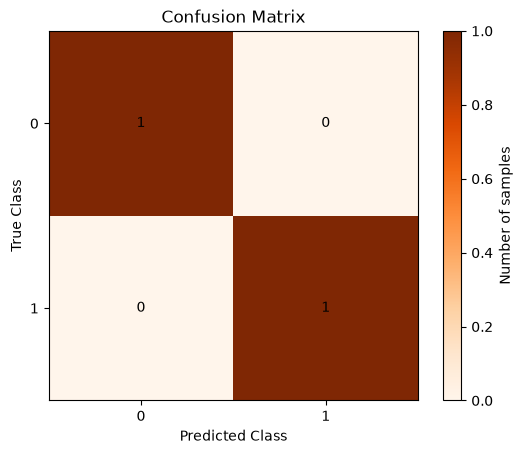


Large Dataset
Accuracy: 0.9380530973451328
Confusion Matrix:
[[40  2]
 [ 5 66]]
Precision: [0.8888888888888888, 0.9705882352941176]
Recall: [0.9523809523809523, 0.9295774647887324]
F1: [0.9195402298850575, 0.9496402877697842]
Macro Precision: 0.9297385620915033
Macro Recall: 0.9409792085848423
Macro F1: 0.9345902588274209

Large Dataset Confusion Matrix


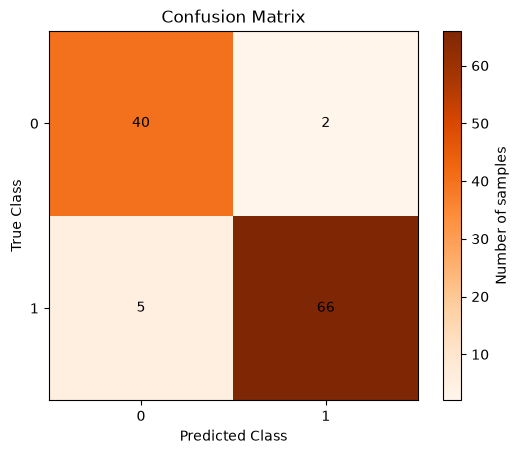

In [198]:
# Tiny Dataset
X_train_small, X_test_small, y_train_small, y_test_small = train_test_split(X, y)
GNB_small = GaussianNaiveBayes()
GNB_small.train(X_train_small, y_train_small)
prob_small = GNB_small.predict_proba(X_test_small)
pred_small = GNB_small.classes[np.argmax(prob_small, axis=1)]
confusion_matrix_small = confusion_matrix(y_test_small, pred_small, GNB_small.classes)
precision, recall, f1, macro_p, macro_r, macro_f1 = precision_recall_f1(y_test_small, pred_small, GNB_small.classes)

print("Small Dataset")
print("Accuracy:", accuracy(y_test_small, pred_small))
print("Confusion Matrix:")
print(confusion_matrix_small)
print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)
print("Macro Precision:", macro_p)
print("Macro Recall:", macro_r)
print("Macro F1:", macro_f1)
print("\nSmall Dataset Confusion Matrix")
plot_confusion_matrix(confusion_matrix_small, GNB_small.classes)


# Large Dataset
GNB_large = GaussianNaiveBayes()
GNB_large.train(x_train, y_train)
prob_large = GNB_large.predict_proba(x_test)
pred_large = GNB_large.classes[np.argmax(prob_large, axis=1)]
confusion_matrix_large = confusion_matrix(y_test, pred_large, GNB_large.classes)
precision, recall, f1, macro_p, macro_r, macro_f1 = precision_recall_f1(y_test, pred_large, GNB_large.classes)

print("\nLarge Dataset")
print("Accuracy:", accuracy(y_test, pred_large))
print("Confusion Matrix:")
print(confusion_matrix_large)
print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)
print("Macro Precision:", macro_p)
print("Macro Recall:", macro_r)
print("Macro F1:", macro_f1)
print("\nLarge Dataset Confusion Matrix")
plot_confusion_matrix(confusion_matrix_large, GNB_large.classes)